# Architecture in the cloud, monitoring and maintenance

After this block you can sketch the architecture of a data application (front end, back end, database) and name the cloud services that run each part, and you can keep a deployed model useful: measure data drift with the KS test and the population stability index, detect label shift once labels arrive, decide on retraining with a written rule, and document the model in a model card. This serves the second and third learning outcomes of Session 16.

The case study provides real examples. After Brexit the United Kingdom issues no more customs decisions; the mix of goods changes from year to year; the labels of 2024 are released in this session as feedback. The block ends with the final leaderboard round **L3**: version 2 of the model, retrained with the 2024 labels.

## Teaching map

The **core path** for the 45-minute lecture is marked with ●. Subsections marked *(depth: self-study or if time allows)* go further and can be skipped in class.

| Section | Minutes | What it delivers |
|---|---|---|
| ● System design: front end, back end, database | 7 | the three parts, Docker Compose, a prediction log in SQLite |
| ● Cloud services on AWS | 5 | registry, container hosting, managed database, file storage, monitoring (introduction) |
| ● Monitoring: data drift | 12 | KS test and PSI on the 2024 requests; GB after Brexit |
| ● Monitoring: prediction drift and label shift | 8 | the 2024 labels arrive: chapter shares, unseen headings, accuracy |
| ● Retraining triggers and versioning | 8 | a written rule, candidates compared on the newest labels |
| ● Documenting a model in a model card | 5 | sections, results per language, a card generated with skops |
| Worked example · final leaderboard round L3 | team project | version 2 and the submission file |
| **Total core** | **45** | |

```mermaid
flowchart LR
    S["Service v1<br/>in production"] --> L["Prediction log<br/>(database)"]
    L --> I["Without labels:<br/>input drift,<br/>prediction drift"]
    F["Labels arrive later<br/>(2024 feedback)"] --> P["With labels:<br/>label shift, accuracy"]
    I --> R{"Retraining rule"}
    P --> R
    R -->|no| S
    R -->|yes| T["Retrain candidates,<br/>compare on newest data"]
    T --> V["Release v2,<br/>update model card"]
    V --> S
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

**Setup.** Next we load the training sample (decisions 2017 to 2023), the test requests of 2024 to 2026 (descriptions without labels) and, if the lecturer has released it, the feedback file with the labels of 2024 (`case-study/data/feedback_2024.csv`, columns `id` and `heading`; another path can be given in the environment variable `FEEDBACK_PATH`). Without the file, the cells that need labels print a message instead.

In [2]:
import numpy as np
import pandas as pd

DATA = Path("case-study/data")
train = pd.read_parquet(DATA / "train_sample.parquet")
test = pd.read_parquet(DATA / "test.parquet")
test["period"] = np.where(test["start_date"].dt.year == 2024, "2024", "2025-26")
t2024 = test[test["period"] == "2024"]
FEEDBACK = Path(os.environ.get("FEEDBACK_PATH", DATA / "feedback_2024.csv"))
feedback = pd.read_csv(FEEDBACK, dtype=str) if FEEDBACK.exists() else None
print(len(train), "training decisions;", test["period"].value_counts().to_dict(), "requests")
print("feedback:", "not released yet" if feedback is None else f"{len(feedback):,} labelled decisions of 2024")

50000 training decisions; {'2025-26': 72819, '2024': 40369} requests
feedback: 40,369 labelled decisions of 2024


Next we train version 1 of the model, as in Block 1 but on the whole training sample: word TF-IDF and a linear SVM. This is the model "in production" during 2024. `n_jobs=-1` trains the one-against-the-rest classifiers of the headings on all processor cores. About 15 to 60 seconds, depending on the machine.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline

def make_model():
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2),
                         SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0,
                                       n_jobs=-1))                         # all processor cores

v1 = make_model().fit(train["description"], train["heading"])
test["pred_v1"] = v1.predict(test["description"])
t2024 = test[test["period"] == "2024"]
print(len(v1.classes_), "headings known to v1")

934 headings known to v1


## System design: front end, back end and database

This section and the next are an introduction. The aim is that you can read and sketch the architecture of a data application and know which cloud services exist for each part, not that you operate them.

**System design** is the decision about which parts an application consists of, what each part does and how the parts communicate. Most data applications follow the same three-part pattern:

| Part | What it does | In the tariff example |
|---|---|---|
| **Front end** | what users see and click: a web page or a dashboard | a Streamlit dashboard where an officer pastes a description |
| **Back end** | the logic behind it, offered as an API: validation, the model, the rules | the FastAPI service of Block 1 that returns the top three headings |
| **Database** | data that must outlive a single request | a SQLite file with the prediction log, the raw material of monitoring |

```mermaid
flowchart LR
    U["User<br/>(browser)"] -->|HTTPS| FE["Front end<br/>Streamlit dashboard"]
    FE -->|"HTTP + JSON<br/>POST /predict"| BE["Back end<br/>FastAPI + model"]
    P["Other programs"] -->|"HTTP + JSON"| BE
    BE -->|SQL| DB[("Database<br/>SQLite file")]
```

The parts talk over the network: the front end sends HTTP requests with JSON to the back end (Block 1), the back end sends SQL to the database (Session 3). Only the front end and the API are reachable from outside; the database is not. Why separate the parts instead of writing one script?

- **One model, several clients.** The dashboard, a batch job and another team's software all use the same API, and a new model version is deployed in one place.
- **Independent scaling.** If many requests arrive, more copies of the back end are started; the database stays one.
- **Security.** The database holds the data and is reachable only from the back end, never from the internet.
- **Replaceable parts.** The Streamlit front end can later become a web page without touching the model.

Not every project needs all three parts. Three common designs:

| Design | Parts | Example |
|---|---|---|
| Interactive model service | front end → back end → database | the tariff heading service of the workspace |
| Analytics dashboard | front end → database, refreshed by a scheduled job | a dashboard of Berlin rental prices, reloaded every night |
| Batch scoring | scheduled job → database → reporting tool | churn scores computed every Monday for all customers and read by the CRM team |

### Locally: Docker Compose

**Locally**, front end and back end each run in their own container, and **Docker Compose** starts them together from one file, `compose.yaml`. The containers share a private network in which they find each other by service name: the dashboard calls `http://api:8000`. The database is a SQLite file on a **volume**, a storage area that Docker keeps when a container is replaced. Only the API container mounts it, so the log survives a restart and cannot be reached from outside. `workspace/compose.yaml`, shortened:

```yaml
services:
  api:                                    # back end: the image of the Dockerfile (Block 1)
    build: .
    environment: {PREDICTION_DB: /app/data/predictions.sqlite}
    volumes: ["prediction-data:/app/data"]   # database: a SQLite file that only the API sees
    ports: ["8000:8000"]
  dashboard:                              # front end: sends every description to the API
    build: dashboard
    environment: {API_URL: "http://api:8000"}
    depends_on: {api: {condition: service_healthy}}
    ports: ["8501:8501"]
volumes:
  prediction-data:
```

```bash
cd sessions/16-deployment-and-monitoring/workspace
docker compose up --build        # dashboard: http://localhost:8501, API: http://localhost:8000/docs
docker compose logs api          # what the API printed
docker compose down              # add -v to delete the volume with the log as well
```

The service code hardly changes: with the environment variable `PREDICTION_DB` set, the API writes its prediction log to a SQLite table, and with `API_URL` set, the dashboard calls the API instead of loading the model. Settings that differ between laptop and cloud come from the environment, not from the code.

### The database part: a prediction log

Monitoring needs a record of what the service did. The workspace's `SQLitePredictionLogger` writes one row per request: time, model version, description length, language, top heading and its score. It deliberately does **not** store the description, which is confidential business information before a decision.

Next we play one month of service: v1 answers the 2024 requests of January, and we log them into a SQLite database. `sqlite3.connect(":memory:")` creates a database that lives only in memory (nothing is written to disk), and `executemany` inserts many rows in one call. `decision_function` gives the margin of every heading; `.max(axis=1)` keeps the top score.

In [4]:
import sqlite3

db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE predictions (time TEXT, model_version TEXT, text_length INTEGER, "
           "language TEXT, heading TEXT, top_score REAL)")
jan = t2024[t2024["start_date"] < "2024-02-01"]
top_score = v1.decision_function(jan["description"]).max(axis=1)
rows = zip(jan["start_date"].astype(str), ["1.0.0"] * len(jan), jan["description"].str.len().tolist(),
           jan["language"], jan["pred_v1"], top_score.round(3).tolist())
db.executemany("INSERT INTO predictions VALUES (?, ?, ?, ?, ?, ?)", rows)
print(db.execute("SELECT COUNT(*) FROM predictions").fetchone()[0], "logged predictions")

3427 logged predictions


**Predict before running.** For which language do you expect the lowest average top score, the one most heavily represented in training or a rare one? The SQL query groups the log by language (Session 3).

In [5]:
query = '''SELECT language, COUNT(*) AS n, ROUND(AVG(top_score), 3) AS mean_score,
                  ROUND(AVG(top_score < 0), 3) AS share_unsure
           FROM predictions GROUP BY language HAVING n >= 100 ORDER BY n DESC'''
pd.read_sql(query, db)

,language,n,mean_score,share_unsure
0,de,2011,0.965,0.093
1,fr,610,0.099,0.495
2,nl,129,-0.327,0.806
3,cs,113,-0.218,0.690
4,pl,100,-0.247,0.700


**Reading the result.** The log alone, without any label, already shows where the model is unsure: a negative top score means the model does not really vote for any heading. This is the first monitoring signal, and it is available on day one. The rest of this notebook computes the others from the same kind of data.

One SQLite file serves one API container well. When several copies of the back end on different machines must write to the same data, the SQLite documentation recommends a client/server database instead, and that is what the cloud offers as a managed service.

### Publishing a dashboard *(depth: self-study or if time allows)*

Not every model needs an API. For many projects, the users are people who want to explore results: a **dashboard** is a web page with charts, filters and perhaps a form that calls the model. **Streamlit** turns a Python script into such a web app: every widget (`st.text_area`, `st.selectbox`) is a line of Python, and the script reruns when the user changes an input. `@st.cache_resource` keeps the loaded model in memory between reruns. The core of `workspace/dashboard/streamlit_app.py` (shown, not run):

```python
# requires: uv sync --extra dashboard, then: MODEL_DIR=models uv run streamlit run dashboard/streamlit_app.py
import os
from pathlib import Path

import pandas as pd
import streamlit as st

from tariff_service.model import decision_text, load_model, top_k

@st.cache_resource                      # load once per server process
def get_model():
    return load_model(Path(os.environ.get("MODEL_DIR", "models")))

pipe, meta = get_model()
st.title("Tariff heading suggestion")
st.caption(f"Model {meta['model_version']} · validation accuracy {meta['validation']['accuracy']}")
text = st.text_area("Description of goods", "Masque de protection à usage unique, en non-tissé")
ranked = top_k(pipe, [decision_text(text)], k=3)[0]          # [(heading, score), ...]
st.dataframe(pd.DataFrame([{"heading": h, "score": sc, "text": meta["headings"].get(h, "")}
                           for h, sc in ranked]))
```

Publishing options differ in what they run and what they cost; free tiers change often, so check the current terms before you choose.

| Option | Runs | Fits | Notes |
|---|---|---|---|
| Streamlit Community Cloud | Streamlit apps from a public GitHub repository | team dashboards, course projects | free; the app sleeps when unused |
| Hugging Face Spaces | Gradio, Streamlit, static and Docker apps | model demos | free hardware only for some app types |
| Render, Google Cloud Run and similar | any container image | the API container | free quotas with limits; some need a billing account |
| A university or company server | containers with Docker or Podman | internal or personal data | data stay inside the organisation |
| A static report (Quarto, Jupyter Book on GitHub Pages) | HTML without a server | results that need no live predictions | cheapest and most robust |

```mermaid
flowchart TD
    Q{"Do users need live<br/>predictions?"} -->|no| ST["Static report:<br/>GitHub Pages"]
    Q -->|yes| P{"Are the users<br/>people or programs?"}
    P -->|programs| API["API container:<br/>Cloud Run, Render, server"]
    P -->|people| D{"Personal or<br/>confidential data?"}
    D -->|yes| IN["Internal server<br/>or company cloud"]
    D -->|no| SC["Streamlit Community Cloud<br/>or Hugging Face Spaces"]
```

A public free tier is fine for a demo on published BTI decisions, not for pending requests, which contain confidential business information. A public dashboard is public: anyone can use it, and every prediction costs computing time.

## Cloud services for the application on AWS

**In the cloud**, the same three parts run on managed services: the provider runs the machines, installs updates and makes backups, and you pay for what you use. Amazon Web Services (AWS) offers a service for each part:

| Part | Locally (Compose) | AWS service | What the service does |
|---|---|---|---|
| Container images | `docker build` | **Amazon ECR** (Elastic Container Registry) | stores the images that CI builds |
| Front end and back end | containers `dashboard`, `api` | **Amazon ECS with AWS Fargate** | runs containers without managing servers; starts more copies under load |
| Entry point | `ports:` | **Elastic Load Balancing** (Application Load Balancer) | receives HTTPS traffic and spreads it over the containers |
| Database | SQLite file on a volume | **Amazon RDS** (Relational Database Service) | a managed SQL database server (for example PostgreSQL) with backups and updates |
| Files: model, raw data | `models/` folder | **Amazon S3** | object storage for files of any size |
| Passwords and keys | `environment:` | **AWS Secrets Manager** | stores secrets and passes them to the containers |
| Logs, metrics, alarms | `docker compose logs` | **Amazon CloudWatch** | collects logs and metrics and raises alarms |

```mermaid
flowchart LR
    GH["GitHub Actions<br/>(cd.yml)"] -->|push image| ECR["Amazon ECR"]
    U["Users"] -->|HTTPS| LB["Load balancer"]
    subgraph ECS["Amazon ECS on Fargate"]
        FE["dashboard<br/>container"]
        BE["api<br/>containers"]
    end
    ECR -.->|pull| ECS
    LB --> FE
    LB --> BE
    FE --> BE
    BE --> RDS[("Amazon RDS<br/>SQL database")]
    BE -.->|model files| S3["Amazon S3"]
    ECS -.->|logs, metrics| CW["Amazon CloudWatch"]
```

Read the diagram as the story of one release: CD pushes the image to ECR (Block 1); ECS pulls it and runs the containers; the load balancer sends users to them; the API writes its prediction log to RDS and reads the model from S3; CloudWatch collects the logs and raises an alarm when, for example, the share of unsure answers rises. Microsoft Azure and Google Cloud offer the same building blocks under other names, for example Azure Container Apps or Google Cloud Run for the containers and Azure SQL Database or Google Cloud SQL for the database. The design stays the same; only the names change.

Data scientists rarely set up cloud infrastructure alone, but they take part in the decisions: where the model runs, where the data live, who can reach them and what it costs. An architecture sketch is the common language for these discussions with engineers, IT security and the budget holder. It also makes data protection visible: in the diagram you can point to the one place where confidential requests could be stored (here: nowhere, because the log keeps no descriptions).

In practice, AWS, Azure and Google Cloud each publish a *well-architected framework* with design principles for reliability, security, cost and performance, and companies with many services often move from ECS to Kubernetes (Amazon EKS, Azure AKS, Google GKE).

> **Note.** Cloud resources cost money while they exist, whether or not anyone uses them: a load balancer and a database are billed by the hour. Free offers for new accounts are limited in time and amount, and their terms change; check them, set a budget alarm, and delete what you created after an experiment.

## Monitoring: data drift with the KS test and the population stability index

A deployed model starts to age on its first day. The requests change, the goods change, the member states that send requests change, and the nomenclature itself is revised every five to six years (HS 2017, HS 2022, and HS 2028, effective 1 January 2028 according to the World Customs Organization, checked October 2026). **Monitoring** compares what the service sees now with what it was trained on.

**Data drift** (also *covariate shift*) is a change in the distribution of the inputs between the **reference** data (training or validation data) and the **current** data (recent requests). Labels arrive late (a year later in the case study) or never, but inputs are available at once, so input drift is the earliest warning that the model is used on data unlike its training data. For text we monitor summaries of the input: the length of the description, the language, the issuing country, the share of words the model has never seen.

### The Kolmogorov–Smirnov test

For one numeric feature, the two-sample **KS test** compares the two **empirical distribution functions** (ECDF): for every value t, the share of observations at or below t. Its statistic D is the largest vertical distance between the two curves, from 0 (identical) to 1 (no overlap). A worked example: reference [1, 2, 3, 4], current [3, 4, 5, 6]. At t = 2, 50 % of the reference and 0 % of the current values are at or below t; no point has a larger gap, so D = 0.5. `scipy.stats.ks_2samp` computes D and a p-value; next we check the hand calculation.

In [6]:
from scipy import stats

stats.ks_2samp([1, 2, 3, 4], [3, 4, 5, 6]).statistic

np.float64(0.5)

Next we compare the length of the descriptions (on a log scale, because a few are very long) in the training data and in the 2024 requests. `np.log1p(x)` computes log(1 + x).

**Predict before running.** Do the 2024 descriptions look very different in length? Guess D: about 0.01, 0.1 or 0.5?

In [7]:
ref_len = np.log1p(train["description"].str.len())
cur_len = np.log1p(t2024["description"].str.len())
ks = stats.ks_2samp(ref_len, cur_len)
print(f"D = {ks.statistic:.3f}, p = {ks.pvalue:.0e}")

D = 0.071, p = 3e-97


Next we draw the two ECDFs and mark where the gap D is largest, to see what the statistic measures. `np.searchsorted(sorted_values, grid, side="right") / n` evaluates an ECDF at many points at once.

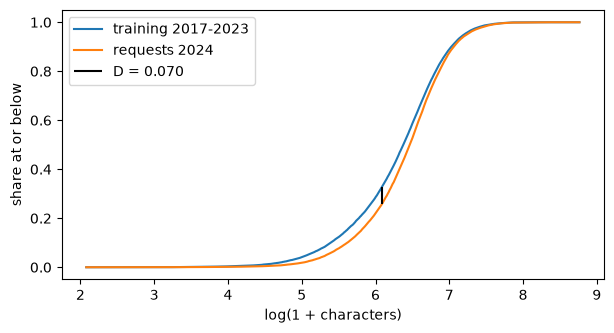

In [8]:
import matplotlib.pyplot as plt

grid = np.linspace(min(ref_len.min(), cur_len.min()), max(ref_len.max(), cur_len.max()), 500)
F_ref = np.searchsorted(np.sort(ref_len), grid, side="right") / len(ref_len)
F_cur = np.searchsorted(np.sort(cur_len), grid, side="right") / len(cur_len)
i = np.argmax(np.abs(F_ref - F_cur))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, F_ref, label="training 2017-2023")
ax.plot(grid, F_cur, label="requests 2024")
ax.vlines(grid[i], F_ref[i], F_cur[i], color="black", label=f"D = {abs(F_ref[i] - F_cur[i]):.3f}")
ax.set(xlabel="log(1 + characters)", ylabel="share at or below")
ax.legend(); plt.show()

### p-values and large samples

The p-value above is tiny, so the test calls the difference "significant". But the curves almost coincide. With tens of thousands of requests, the KS test finds even irrelevant differences significant: the p-value measures how sure we are that there is *some* difference, not how *large* it is. Next we take random samples of growing size from both groups and watch D stay roughly constant while the p-value collapses. `.sample(n, random_state=0)` draws a reproducible sample.

In [9]:
for n in [200, 1_000, 5_000, 40_000]:
    r = stats.ks_2samp(ref_len.sample(n, random_state=0), cur_len.sample(n, random_state=0))
    print(f"n = {n:>6}: D = {r.statistic:.3f}, p = {r.pvalue:.1e}")

n =    200: D = 0.105, p = 2.2e-01
n =   1000: D = 0.106, p = 2.6e-05
n =   5000: D = 0.065, p = 1.7e-09
n =  40000: D = 0.071, p = 1.3e-87


> **Note.** Judge the size of the shift (D, PSI) and its effect on the model, not the p-value. With large logs, a test-based alarm fires every day.

### The population stability index

The **PSI** works for numeric and categorical features and has an interpretable scale. Divide the reference into bins (for a numeric feature usually its deciles, so that each bin holds 10 % of the reference; for a categorical feature one bin per category), compute the share p of the reference and q of the current data in each bin, and sum

PSI = Σ (q − p) · ln(q / p).

Each term is never negative: if q is larger than p, both factors are positive; if smaller, both are negative. A worked example with two bins: p = (0.5, 0.5), q = (0.6, 0.4). Then 0.1 · ln 1.2 + (−0.1) · ln 0.8 = 0.0182 + 0.0223 = 0.041. A common rule of thumb from credit scoring (Siddiqi 2006): **below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 large shift**.

A category that disappears (q = 0) makes ln(q / p) infinite. In practice the shares are clipped at a small value such as 0.0001, so a vanished category contributes a large but finite amount. The choice of that value changes the result, so it must be stated.

Next we write two small functions: `psi_shares` for categories given as `{category: share}` dictionaries, and `psi` for a numeric feature with decile bins. `np.quantile` finds the bin edges of the reference, `np.searchsorted` puts every value into its bin and `np.bincount` counts the bins. `np.clip(x, eps, None)` replaces values below `eps`.

In [10]:
def psi_shares(p, q, eps=1e-4):                       # categorical: {category: share}
    cats = sorted(set(p) | set(q))
    p = np.clip([p.get(c, 0) for c in cats], eps, None)
    q = np.clip([q.get(c, 0) for c in cats], eps, None)
    return float(np.sum((q - p) * np.log(q / p)))

def psi(reference, current, bins=10, eps=1e-4):       # numeric: decile bins of the reference
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1))[1:-1])
    p = np.bincount(np.searchsorted(edges, reference, side="right"), minlength=len(edges) + 1) / len(reference)
    q = np.bincount(np.searchsorted(edges, current, side="right"), minlength=len(edges) + 1) / len(current)
    p, q = np.clip(p, eps, None), np.clip(q, eps, None)
    return float(np.sum((q - p) * np.log(q / p)))

print(round(psi_shares({"a": 0.5, "b": 0.5}, {"a": 0.6, "b": 0.4}), 3), "| length PSI 2024:", round(psi(ref_len, cur_len), 3))

0.041 | length PSI 2024: 0.035


Description length is stable. Next the issuing country, a categorical input. `value_counts(normalize=True).to_dict()` gives the shares as a dictionary.

**Predict before running.** Which country will contribute most to the PSI, and why?

In [11]:
shares = lambda s: s.value_counts(normalize=True).to_dict()
p_country, q_country = shares(train["issuing_country"]), shares(t2024["issuing_country"])
print("country PSI 2024:", round(psi_shares(p_country, q_country), 3))
contrib = pd.DataFrame({"p_train": pd.Series(p_country), "q_2024": pd.Series(q_country)}).fillna(0)
pc, qc = contrib["p_train"].clip(1e-4), contrib["q_2024"].clip(1e-4)
contrib["contribution"] = (qc - pc) * np.log(qc / pc)
contrib.sort_values("contribution", ascending=False).head(5).round(4)

country PSI 2024: 0.239


,p_train,q_2024,contribution
GB,0.0362,0.0000,0.2124
IE,0.0138,0.0064,0.0057
DE,0.5583,0.6160,0.0057
BE,0.0126,0.0080,0.0021
CZ,0.0260,0.0339,0.0021


**Reading the result.** Almost the whole PSI comes from one country: the United Kingdom issued about 4 % of the training decisions and none in 2024, because UK decisions ended with the Brexit transition period. This is a change in the world, not an error in the data pipeline. Since all UK decisions were written in English, the language mix moves as well. Next we check the language PSI and the share of English.

In [12]:
p_lang, q_lang = shares(train["language"]), shares(t2024["language"])
print("language PSI 2024:", round(psi_shares(p_lang, q_lang), 3),
      "| English:", round(p_lang["en"], 3), "->", round(q_lang["en"], 3))
print("GB decisions per year in training:",
      train.loc[train["issuing_country"] == "GB", "start_date"].dt.year.value_counts().sort_index().to_dict())

language PSI 2024: 0.095 | English: 0.052 -> 0.009
GB decisions per year in training: {2017: 549, 2018: 461, 2019: 406, 2020: 392}


The UK decisions stopped after 2020, so the shift was already visible inside the training data. A monitoring system that compares with all training years flags it every month; one that compares with the most recent year does not. The choice of the **reference period** is a decision, and it belongs in the monitoring plan.

The course figures show both views: the country shares over time, and the PSI broken down by country.

![Left: shares of issuing countries in the training data, 2024 and 2025-2026 on a log scale; GB falls from 3.6 % to zero. Right: change of chapter shares from 2023 to 2024](../figures/drift-histogram.png)

![Upper: shares of the eight countries with the largest contributions in the reference and in 2024; lower: their contributions to the country PSI, almost all from GB](../figures/psi-explained.png)

### PSI depends on the binning *(depth: self-study or if time allows)*

PSI is computed from bins, so the number of bins changes the number. Next we recompute the length PSI with 5, 10 and 20 bins. Compute the bin edges once, store them with the model (the workspace keeps them in `metadata.json`) and reuse them for every check; otherwise the numbers of different months are not comparable.

In [13]:
{bins: round(psi(ref_len, cur_len, bins=bins), 4) for bins in [5, 10, 20]}

{5: 0.0298, 10: 0.0349, 20: 0.039}

### Other drift measures and drift reports *(depth: self-study or if time allows)*

Monitoring tools compute such statistics for every column of the input and summarise them in a **drift report**. The open-source library Evidently is one of them. According to its documentation (checked October 2026), its default data-drift preset tests each column on its own and chooses the method by data size and type:

- with up to 1,000 reference rows: the KS test for numeric columns and the chi-squared test for categorical ones, drift if p < 0.05;
- with more rows: the **Wasserstein distance** (normed) for numeric columns and the **Jensen–Shannon distance** for categorical ones, drift if the value is at least 0.1;
- for text columns: a **domain classifier** (below), drift if its ROC AUC exceeds 0.55;
- the dataset as a whole counts as drifted when at least half of its columns drift (`drift_share=0.5`).

The switch from tests to distances for larger data follows from the p-value problem shown above. The **Wasserstein distance** is the average amount by which values must be moved to turn one distribution into the other (the *earth mover's distance*); dividing it by the standard deviation of the reference makes it comparable across features. The **Jensen–Shannon distance** compares two sets of category shares; it is 0 for identical shares and 1 for no overlap (with base-2 logarithms), and unlike PSI it stays finite when a category vanishes.

Next we build a small drift report in that spirit for three columns of the 2024 requests: `scipy.stats.wasserstein_distance` and `scipy.spatial.distance.jensenshannon` compute the two distances.

In [14]:
from scipy.spatial.distance import jensenshannon

def js(p, q):
    cats = sorted(set(p) | set(q))
    return float(jensenshannon([p.get(c, 0) for c in cats], [q.get(c, 0) for c in cats], base=2))

report = pd.DataFrame([
    {"column": "log length", "method": "Wasserstein (normed)",
     "value": stats.wasserstein_distance(ref_len, cur_len) / ref_len.std(), "psi": psi(ref_len, cur_len)},
    {"column": "language", "method": "Jensen-Shannon", "value": js(p_lang, q_lang), "psi": psi_shares(p_lang, q_lang)},
    {"column": "issuing_country", "method": "Jensen-Shannon", "value": js(p_country, q_country),
     "psi": psi_shares(p_country, q_country)}])
report["drift (>= 0.1)"] = report["value"] >= 0.1
report.round(3)

,column,method,value,psi,drift (>= 0.1)
0,log length,Wasserstein (normed),0.169,0.035,True
1,language,Jensen-Shannon,0.124,0.095,True
2,issuing_country,Jensen-Shannon,0.151,0.239,True


**Reading the result.** By the distances and the 0.1 threshold, how many of the three columns drift, and does the report agree with the PSI rule of thumb? Different measures put the line in different places; a monitoring plan names one measure and one threshold per column, and keeps them fixed.

**Text drift with a domain classifier.** Summaries such as length miss changes in *what* is described. Evidently's text method trains a classifier to tell reference texts from current texts: if it cannot (ROC AUC near 0.5), the texts look alike; if it can, the content has shifted. Next we try this for three pairs of periods of equal size. `cross_val_predict` gives every description a score from a model that did not see it, and `roc_auc_score` measures how well the scores separate the two periods.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

def domain_auc(ref_texts, cur_texts, n=3000):
    texts = pd.concat([ref_texts.sample(n, random_state=0), cur_texts.sample(n, random_state=0)])
    is_current = np.r_[np.zeros(n), np.ones(n)]
    clf = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), LogisticRegression(max_iter=1000))
    scores = cross_val_predict(clf, texts, is_current, cv=5, method="predict_proba")[:, 1]
    return round(roc_auc_score(is_current, scores), 3)

by_year = lambda y: train.loc[train["start_date"].dt.year == y, "description"]
{"2022 vs 2023": domain_auc(by_year(2022), by_year(2023)),
 "2023 vs 2024": domain_auc(by_year(2023), t2024["description"]),
 "2017 vs 2024": domain_auc(by_year(2017), t2024["description"])}

{'2022 vs 2023': 0.628, '2023 vs 2024': 0.624, '2017 vs 2024': 0.802}

**Reading the result.** Compare each AUC with 0.5 (no difference) and with Evidently's threshold of 0.55. Even neighbouring years can be told apart a little (and would already exceed Evidently's default threshold, so that threshold needs tuning for this data), and the separation grows with distance in time: new products, new wording, other member states. The classifier can also show *which* words separate the periods, which is a good start for an investigation.

> 📖 **Read more:** [extras/02-evidently-data-drift-report.ipynb](extras/02-evidently-data-drift-report.ipynb) (Evidently, Apache-2.0): the same idea as a ready-made report with `DataDriftPreset` and `DataSummaryPreset` on the Adult census data.

### Words the model has never seen *(depth: self-study or if time allows)*

The **out-of-vocabulary (OOV) rate** is the share of words in new requests that are not in the model's vocabulary. A rising OOV rate means new product names and terms that the model simply cannot use. Next we compute it for a sample of 5,000 descriptions per period. The regular expression `\b\w\w+\b` matches the words that `TfidfVectorizer` uses by default (two or more word characters), and `vocabulary_` is the fitted vocabulary.

In [16]:
import re

TOKEN = re.compile(r"(?u)\b\w\w+\b")
vocab = set(v1.named_steps["tfidfvectorizer"].vocabulary_)

def oov_rate(texts):
    words = [w for t in texts for w in TOKEN.findall(t.lower())]
    return round(sum(w not in vocab for w in words) / len(words), 4)

{"2023 (in training)": oov_rate(by_year(2023).sample(5000, random_state=0)),
 "2024": oov_rate(t2024["description"].sample(5000, random_state=0)),
 "2025-26": oov_rate(test.loc[test["period"] == "2025-26", "description"].sample(5000, random_state=0))}

{'2023 (in training)': 0.0304, '2024': 0.0552, '2025-26': 0.0603}

The 2023 value is the level of "no drift": even training years have unseen words, because `min_df=2` drops words that occur only once. The workspace has the tested versions of these functions in `workspace/src/tariff_service/drift.py`, and `python -m tariff_service.monitor` prints a drift report from the command line.

In practice, credit-scoring teams have used PSI for decades to check whether the applicant population still matches the development sample of a scorecard (Siddiqi 2006), and during the COVID-19 pandemic many demand-forecasting and fraud models failed because behaviour changed abruptly (Heaven, *MIT Technology Review*, 2020).

## Monitoring: prediction drift and label shift

Three kinds of shift, written with the input x and the label y:

| Shift | What changes | Measurable | Effect on the model |
|---|---|---|---|
| **data drift** (covariate shift) | P(x): the inputs | at once | may or may not hurt |
| **label shift** (prior shift) | P(y): the heading or chapter shares | when labels arrive | changes the mix of errors |
| **concept drift** | P(y given x): what an input means | when labels arrive | makes the model wrong |

**Concept drift** has a concrete form in tariff classification: the **nomenclature revision**. With HS 2022, some headings were created (for example 8524, flat panel display modules, and 2404, nicotine products), others were split or deleted. The same description of goods then belongs to a different heading. A model trained on older decisions cannot predict a heading it has never seen; the share of such **unseen headings** among new labels measures this directly.

**Prediction drift** is a change in the distribution of the model's *outputs*. It can be measured at once, without labels, and is often the first sign of label shift. Next we compare the chapter shares (the first two digits of the heading) in the training labels with the chapters v1 *predicts* for the 2024 requests. `.str[:2]` takes the first two characters.

In [17]:
p_chapter = shares(train["chapter"])
q_pred = shares(t2024["pred_v1"].str[:2])
print("prediction drift, chapter PSI:", round(psi_shares(p_chapter, q_pred), 3))
print("chapter 85 (electrical machinery): training", round(p_chapter["85"], 3), "| predicted 2024", round(q_pred["85"], 3))

prediction drift, chapter PSI: 0.063
chapter 85 (electrical machinery): training 0.147 | predicted 2024 0.12


The model predicts fewer electrical goods in 2024 than the training data contained. Two explanations are possible: fewer such goods are actually requested (label shift, a fact about trade), or the model has started to miss them (an error of the model). Only labels can tell them apart.

### The 2024 labels arrive

Now the lecturer releases the labels of 2024. Next we join them to the requests with `merge(on="id")` and compare the chapter shares of 2023 (the last training year) with the true shares of 2024.

In [18]:
if feedback is not None:
    fb = t2024.merge(feedback, on="id")
    y2023 = train[train["start_date"].dt.year == 2023]
    chapters = pd.DataFrame({"2023": y2023["chapter"].value_counts(normalize=True),
                             "2024": fb["heading"].str[:2].value_counts(normalize=True)}).fillna(0)
    chapters["change"] = chapters["2024"] - chapters["2023"]
    print("label shift, chapter PSI 2023 -> 2024:", round(psi_shares(chapters["2023"].to_dict(), chapters["2024"].to_dict()), 3))
    display(chapters.reindex(chapters["change"].abs().sort_values(ascending=False).index).head(6).round(4))
else:
    print("No feedback file yet: the lecturer releases it in this block.")

label shift, chapter PSI 2023 -> 2024: 0.052


,2023,2024,change
85,0.1433,0.1172,-0.0262
64,0.0268,0.0440,0.0172
83,0.0245,0.0152,-0.0092
21,0.0308,0.0367,0.0059
42,0.0270,0.0321,0.0051
19,0.0165,0.0116,-0.0049


**Predict before running.** The next cell computes the same PSI over headings instead of chapters. Will it be larger or smaller, and why?

In [19]:
if feedback is not None:
    print("label shift, heading PSI 2023 -> 2024:",
          round(psi_shares(shares(y2023["heading"]), shares(fb["heading"])), 3))

label shift, heading PSI 2023 -> 2024: 0.229


PSI over about a thousand headings is much larger than over 97 chapters, because rare headings fluctuate by chance from year to year. Compare drift statistics only at the same level of aggregation, and prefer the level at which decisions are taken.

Next the two numbers that matter most: the share of 2024 decisions whose heading v1 never saw in training (it cannot get them right), and the accuracy of v1 on 2024. `isin(v1.classes_)` checks membership in the list of known headings.

In [20]:
if feedback is not None:
    unseen = ~fb["heading"].isin(v1.classes_)
    acc_v1_2024 = float((fb["pred_v1"] == fb["heading"]).mean())
    print(f"unseen headings: {unseen.mean():.4f} of the 2024 decisions | v1 accuracy on 2024: {acc_v1_2024:.3f}")
    nomen = pd.read_parquet(DATA / "nomenclature.parquet").set_index("heading")["heading_description"]
    top_unseen = fb.loc[unseen, "heading"].value_counts().head(4)
    display(pd.DataFrame({"n": top_unseen, "text": nomen.reindex(top_unseen.index).str[:60]}))

unseen headings: 0.0041 of the 2024 decisions | v1 accuracy on 2024: 0.803


,n,text
heading,,
4013,22,"Inner tubes, of rubber"
2828,8,Hypochlorites; commercial calcium hypochlorite...
5902,8,Textile fabrics; tyrecord of high tenacity yar...
8102,7,"Molybdenum; articles thereof, including waste ..."


**Reading the result.** The chapter mix shifts moderately, a few 2024 headings were never seen, and still the accuracy of v1 on 2024 is not lower than its time-based validation accuracy of about 0.78 (Block 1): the model was trained on the years closest to 2024. Label shift and data drift without a loss of quality. In practice, Lipton, Wang and Smola (2018) showed how label shift can be detected and corrected with the confusion matrix of a black-box classifier, and the World Customs Organization publishes correlation tables between HS editions so that statistics and models can map old codes to new ones: a nomenclature revision is planned concept drift.

## Retraining triggers and versioning

Drift alerts without a decision rule are noise. A **retraining trigger** is a written rule that says when a new model is trained, for example:

- **performance trigger**: accuracy on newly labelled data falls more than 0.03 below the validation score;
- **drift trigger**: the PSI of an important input exceeds 0.25;
- **schedule**: a new model whenever a new year of labels is available, and after every nomenclature revision.

Retraining is not replacing. The procedure:

1. Train **candidates**: more data, a recent window, a higher weight for recent data.
2. Compare them with the current model **on the newest labelled data**, which none of them saw in training.
3. Release the winner as a new **version** with metadata and model card; keep the old version for a **rollback**.
4. Update the reference statistics for the next monitoring period.

```mermaid
stateDiagram-v2
    [*] --> Candidate: train
    Candidate --> Rejected: worse on newest data
    Candidate --> Production: better, model card written, release tag
    Production --> Monitored: drift and performance checks
    Monitored --> Production: no trigger
    Monitored --> Retired: replaced by a new version
    Retired --> Production: rollback
    Rejected --> [*]
```

Next we write the rule as a function that returns the decision and its reasons, and apply it to the numbers measured above. Decide the rule *before* you look at the new data, and write it into the model card: a rule invented after seeing the numbers can justify any decision.

In [21]:
def retrain_needed(acc_recent, acc_reference, psi_input, tolerance=0.03, psi_threshold=0.25):
    reasons = []
    if acc_recent is not None and acc_recent < acc_reference - tolerance:
        reasons.append(f"accuracy {acc_recent:.3f} < {acc_reference:.3f} - {tolerance}")
    if psi_input > psi_threshold:
        reasons.append(f"input PSI {psi_input:.3f} > {psi_threshold}")
    return bool(reasons), reasons

acc_recent = acc_v1_2024 if feedback is not None else None
print(retrain_needed(acc_recent, acc_reference=0.778, psi_input=psi_shares(p_country, q_country)))

(False, [])


The rule does not fire. Does retraining help anyway? The 2024 labels are both new training data and the only data close to the target period 2025–2026. To compare candidates fairly without touching the hidden 2025–2026 labels, we hold out the last quarter of 2024 (October to December) and train on the rest:

- **A**: v1 as it is, trained on 2017–2023;
- **B**: 2017–2023 plus January to September 2024;
- **C**: a window, 2020–2023 plus January to September 2024 (older years forgotten).

Next we train B and C (about 15 seconds each) and evaluate all three on the held-out quarter. `f1_score(..., average="macro")` gives every heading the same weight.

In [22]:
from sklearn.metrics import accuracy_score, f1_score

if feedback is not None:
    late = fb["start_date"] >= "2024-10-01"
    fb_early, fb_late = fb[~late], fb[late]
    cols = ["description", "heading"]
    candidates = {"A: v1 (2017-2023)": v1,
                  "B: + 2024 Jan-Sep": pd.concat([train[cols], fb_early[cols]]),
                  "C: 2020-2023 + 2024 Jan-Sep": pd.concat([train.loc[train["start_date"].dt.year >= 2020, cols], fb_early[cols]])}
    rows = []
    for name, data in candidates.items():
        model = data if name.startswith("A") else make_model().fit(data["description"], data["heading"])
        pred = model.predict(fb_late["description"])
        rows.append({"candidate": name, "accuracy Oct-Dec 2024": accuracy_score(fb_late["heading"], pred),
                     "macro-F1": f1_score(fb_late["heading"], pred, average="macro")})
    comparison = pd.DataFrame(rows).set_index("candidate").round(3)
    display(comparison)

,accuracy Oct-Dec 2024,macro-F1
candidate,,
A: v1 (2017-2023),0.793,0.541
B: + 2024 Jan-Sep,0.819,0.595
C: 2020-2023 + 2024 Jan-Sep,0.808,0.576


**Is the difference larger than the noise?** The standard error of an accuracy p on n decisions is about √(p(1 − p)/n) (Session 7). Next we compute it for the held-out quarter and express the gain of B over A in standard errors.

In [23]:
if feedback is not None:
    n_late = len(fb_late)
    acc_a, acc_b = comparison.iloc[0, 0], comparison.iloc[1, 0]
    se = np.sqrt(acc_a * (1 - acc_a) / n_late)
    print(f"{n_late} held-out decisions, standard error {se:.4f}, gain B - A = {acc_b - acc_a:.3f} "
          f"= {(acc_b - acc_a) / se:.1f} standard errors")

8979 held-out decisions, standard error 0.0043, gain B - A = 0.026 = 6.1 standard errors


**Reading the result.** B beats A by 2.6 points, about six standard errors, and C, which forgets 2017–2019, is worse than B. The newest labels are the most informative ones, and the old years still add information. And the written performance rule did not fire, yet retraining helps: **a rule that waits for a drop can miss an improvement**. A scheduled retraining whenever a new year of labels arrives is a sound default for the case study.

**Versioning.** The winner is released as **version 2.0.0** (major: new training data), with its own `metadata.json`, a Git tag `v2.0.0`, a CD run that builds a new image, and an updated model card. Version 1.0.0 stays in the registry: a rollback redeploys its image tag. The prediction log records the model version of every answer, so the monitoring of the next months can compare v1 and v2.

In practice, spam and fraud filters are retrained regularly because adversaries adapt to the model, and recommender systems at large platforms are retrained daily or continuously. Zillow closed its home-buying business Zillow Offers in 2021 after its price forecasts failed to keep up with a fast-changing housing market, with losses of several hundred million US dollars: a model that is not maintained can become expensive.

## Documenting a model in a model card

A **model card** (Mitchell et al., 2019) is a short document that accompanies a trained model, written for the people who use, maintain or audit it. It travels with the model when its developers have moved on. Its sections:

1. **Model details**: name, version, date, type, software, licence, developers.
2. **Intended use**: primary uses and users; **out-of-scope** uses.
3. **Factors**: groups or conditions across which performance may differ (language, issuing country, description length, frequency of the heading, year).
4. **Metrics**: which measures and why (accuracy, macro-F1, top-3 accuracy), decision rule, uncertainty.
5. **Evaluation data** and 6. **training data**: what, from when, how labelled.
7. **Quantitative analyses**: results overall *and per factor*.
8. **Ethical and legal considerations**: confidential data, consequences of errors, who decides.
9. **Caveats and recommendations**: known limits, the monitoring and retraining plan.

A card with intended and out-of-scope uses prevents the most likely misuse (here: treating a suggestion as a binding classification), and per-factor results show where the model is weak before users find out. The workspace contains a template, `workspace/MODEL_CARD.md`, pre-filled with the case-study values of version 1.0.0.

Next we compute the most important per-factor result: the accuracy of v1 on the 2024 labels per language. `groupby(...).agg(n=..., accuracy=...)` computes several named summaries at once.

**Predict before running.** The overall accuracy on 2024 is about 0.8. Which languages lie far below?

In [24]:
if feedback is not None:
    by_lang = (fb.assign(correct=fb["heading"] == fb["pred_v1"])
               .groupby("language").agg(n=("correct", "size"), accuracy=("correct", "mean"))
               .sort_values("n", ascending=False))
    display(by_lang.head(8).round(3))

,n,accuracy
language,,
de,25506,0.960
fr,6265,0.636
nl,1489,0.476
cs,1368,0.374
pl,1231,0.510
es,1012,0.577
sv,713,0.421
it,701,0.439


**Reading the result.** The overall accuracy hides very large differences: German is served far better than the other main languages. Two facts explain much of it: German makes up more than half of the training data, and many German descriptions quote their own heading number (Session 13), which almost no other language does. A model card must report such subgroups; a customs office in Prague would otherwise rely on a number that does not hold for its requests.

### Generating the card from code

Generate the quantitative part of the card from code, so that card and model cannot disagree. The library skops builds a card from a scikit-learn model: `card.Card(model)` fills in the hyperparameters and a diagram of the pipeline, `add(**{section: text})` adds sections (a `/` in the name nests a subsection), `add_metrics` adds a metrics table and `add_table` any DataFrame.

*Adapted from [Text Classification with scikit-learn](https://skops.readthedocs.io/en/stable/auto_examples/plot_text_classification.html) (skops developers, MIT).*

Next we build the card of version 1 with the per-language table. `model_diagram=False` leaves out the HTML diagram, and `render()` returns the card as Markdown; we print its first part.

In [25]:
from skops import card

model_card = card.Card(v1, model_diagram=False)
model_card.add(**{
    "Model description": "Word TF-IDF and a linear SVM that suggests four-digit HS headings for a "
                         "description of goods. Version 1.0.0, trained on 50,000 EBTI decisions of 2017-2023.",
    "Model description/Intended uses & limitations": "Suggestions for customs officers, who check every one. "
        "Out of scope: issuing or refusing a Binding Tariff Information decision; use without a person in the loop.",
    "Model description/Evaluation Results": "Evaluated on the released labels of the 2024 requests."})
if feedback is not None:
    model_card.add_metrics(**{"accuracy 2024": round(acc_v1_2024, 3),
                              "macro-F1 2024": round(f1_score(fb["heading"], fb["pred_v1"], average="macro"), 3)})
    model_card.add_table(**{"Accuracy per language (2024)": by_lang.head(8).round(3).reset_index()})
rendered = model_card.render()
print(rendered[:420])
print(rendered[rendered.index("## Evaluation Results"):][:900])


# Model description

Word TF-IDF and a linear SVM that suggests four-digit HS headings for a description of goods. Version 1.0.0, trained on 50,000 EBTI decisions of 2017-2023.

## Intended uses & limitations

Suggestions for customs officers, who check every one. Out of scope: issuing or refusing a Binding Tariff Information decision; use without a person in the loop.

## Training Procedure

[More Information Neede
## Evaluation Results

|     Metric    | Value |
| :-----------: | :---: |
| accuracy 2024 | 0.803 |
| macro-F1 2024 | 0.518 |

# How to Get Started with the Model

[More Information Needed]

# Model Card Authors

This model card is written by following authors:

[More Information Needed]

# Model Card Contact

You can contact the model card authors through following channels:
[More Information Needed]

# Citation

Below you can find information related to citation.

**BibTeX:**
```
[More Information Needed]
```

# Accuracy per language (2024)

| language |   n   | accurac

The skops example also saves the card as `README.md` next to the model file and can push both to the Hugging Face Hub, which shows a model card for every hosted model. Google, Meta and other companies publish model cards or system cards for their released models, and public-sector algorithm registers, for example those of Amsterdam and Helsinki, describe each system's purpose, data and oversight in a similar structured format.

> **Note.** Write the card while you build the model, not after the release. Sections you cannot fill (for example per-language results) show what is still missing in the evaluation.

> 📖 **Read more:** [extras/01-skops-text-classification-model-card.ipynb](extras/01-skops-text-classification-model-card.ipynb) (skops, MIT): the complete example with a confusion-matrix plot, a classification report and saving the card.

## Worked example · Version 2 and the final leaderboard round (L3)

The comparison above favours retraining with the newest labels. Version 2 is therefore trained on all of 2017–2023 plus all of 2024, and it predicts every test request. Only the private part (2025–2026) counts for the final ranking: on the public part (2024) version 2 has seen the labels, so its score there says nothing. The file is written to a temporary folder; copy it into your team repository (not into the course repository) and upload it with a one-page description of your method. About 20 seconds.

In [26]:
import tempfile

if feedback is not None:
    v2_data = pd.concat([train[["description", "heading"]], fb[["description", "heading"]]])
    v2 = make_model().fit(v2_data["description"], v2_data["heading"])
    submission = pd.DataFrame({"id": test["id"], "heading": v2.predict(test["description"])})
    assert len(submission) == len(test) and submission["heading"].str.fullmatch(r"\d{4}").all()
    out = Path(tempfile.mkdtemp()) / "submission_L3.csv"
    submission.to_csv(out, index=False)
    print(len(v2_data), "training decisions; written:", out.name, "with", len(submission), "rows")

90369 training decisions; written: submission_L3.csv with 113188 rows


**Public scores only.** The leaderboard has a public part (2024) and a private part (2025–2026); the private labels stay hidden until the final ranking in Session 18, also in this notebook. The public labels are the released feedback, so the next cell computes the public scores of v1 and v2 from `feedback_2024.csv`, exactly as the leaderboard would. v2 has seen these labels in training, so its public score is near-perfect and says nothing about 2025–2026; only v1's public score is an honest estimate.

In [27]:
if feedback is not None:
    public = submission.merge(feedback, on="id", suffixes=("_v2", ""))
    public = public.merge(test[["id", "pred_v1"]], on="id")
    for name, col in [("v1 (2017-2023)", "pred_v1"), ("v2 (+ 2024 labels, seen in training)", "heading_v2")]:
        print(f"{name:38s} public 2024: accuracy {accuracy_score(public['heading'], public[col]):.3f}, "
              f"macro-F1 {f1_score(public['heading'], public[col], average='macro'):.3f}")

v1 (2017-2023)                         public 2024: accuracy 0.803, macro-F1 0.518


v2 (+ 2024 labels, seen in training)   public 2024: accuracy 0.993, macro-F1 0.984


For the team project, repeat this with your own model: your validation scheme, your candidates compared on the last quarter of 2024, the retraining decision with its evidence, and the numbers for the model card of version 2 (training data and period, validation scores, drift observed, results per language, known limits).

## Check your understanding

1. Reference shares p = (0.25, 0.25, 0.25, 0.25), current q = (0.40, 0.20, 0.20, 0.20). Compute the PSI. Is the shift stable, moderate or large?
2. The KS test of description length gives a tiny p-value on 40,000 requests. What do you report to the head of the classification unit?
3. The predicted share of chapter 85 falls. Name two explanations and how you tell them apart once labels arrive.
4. Why must retraining candidates be compared on data that none of them saw in training? Why did the written rule not fire although retraining helps?
5. Three copies of the API run behind a load balancer. Why is one SQLite file no longer a good place for the prediction log, and which AWS service replaces it?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; the others are good practice at home. Answer *Paper* and *Class* tasks in the markdown cell below the task, *Code* tasks in the empty code cells.

### 2.1 · Draw the architecture from memory

*Paper · 10 min*

> Without looking at the notebook, draw the architecture of the tariff application: front end, back end (the model API) and database, and the arrows between them with the protocol on each arrow (HTTPS, HTTP + JSON, SQL). Then write next to each part the AWS service that would run it in the cloud, and mark the one place where confidential requests could be stored.

*Source:* original exercise for this course; background: [AWS Well-Architected Framework](https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html)

*Your answer:*

### 2.2 · PSI by hand

*Paper · 10 min*

> The shares of the issuing countries, grouped into three groups, in the training data (2017–2023) and in the requests of 2024:
>
> | Group | Training data | 2024 |
> |---|---|---|
> | Germany (DE) | 0.56 | 0.62 |
> | United Kingdom (GB) | 0.04 | 0.00 |
> | all other member states | 0.40 | 0.38 |
>
> Compute the population stability index. Is the shift stable, moderate or large by the usual rule of thumb? Which group contributes most?

*Source:* [Yurdakul (2018), *Statistical properties of population stability index*, PhD thesis, Western Michigan University](https://scholarworks.wmich.edu/dissertations/3208/)

*Your answer:*

### 2.3 · Country drift, one period later

*Code · 15 min*

> The notebook computed the PSI of the issuing country between the training sample and the requests of 2024. Compute it for the requests of 2025–2026 (the rest of `test`). Then compute it again for both periods with all GB decisions removed from the reference and from the current data. What do the four numbers say about the drift that is left once the United Kingdom is taken out?

*Source:* original exercise for this course

### 2.4 · Feedback loops

*Class · 5 min*

> Customs officers start accepting the model's suggestions, more and more often without changing them. What happens to next year's training labels, and to the accuracy you measure on them?

*Source:* [Sculley et al. (2015), "Hidden technical debt in machine learning systems", NeurIPS](https://papers.nips.cc/paper_files/paper/2015/hash/86df7dcfd896fcaf2674f757a2463eba-Abstract.html)

*Your answer:*

### 2.5 · Results per country for the model card

*Code · 15 min*

*Stretch:*

> The model card should report results per factor. The notebook showed them per language. Using `fb` (the 2024 requests with their labels and the predictions of v1 in `pred_v1`), compute the accuracy per issuing country for the countries with at least 500 decisions. Which countries are served worst, and is the issuing country a separate factor from the language?

*Source:* original exercise for this course; background: [Mitchell et al. (2019), Model Cards for Model Reporting](https://arxiv.org/abs/1810.03993)

## Debrief (15 min)

- **2.1.** Compare two drawings. Typical mistakes: an arrow from the browser straight to the database, the database reachable from the internet, or the model file stored in the database. Ask where the confidential descriptions end up.
- **2.2.** Look for a share of zero: ln(0) has no value, and the result depends on the small number put in its place, which must be stated. Ask two pairs that chose different replacement values to compare their results.
- **2.3.** Compare a drift conclusion based on the size of the shift with one based on a p-value. What should the monitoring plan do about GB: update the reference, or retrain?
- **2.4.** The model starts to learn from its own suggestions; errors that officers no longer correct become "labels", and measured accuracy rises while real quality may not.
- **Bridge to the final presentations.** The team project ends here: service and dashboard run together with Docker Compose and are released through the CI/CD workflow; the release has a tested service, a monitoring plan and a model card; the final model is retrained with the 2024 labels and submitted as round L3; the repository is tagged.

## Further reading

- Docker Inc. *Docker Compose: How Compose works*. [docs.docker.com/compose](https://docs.docker.com/compose/intro/compose-application-model/)
- Amazon Web Services. *AWS Well-Architected Framework*. [docs.aws.amazon.com/wellarchitected](https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html)
- Amazon Web Services. *What is Amazon Elastic Container Service?* [docs.aws.amazon.com/AmazonECS](https://docs.aws.amazon.com/AmazonECS/latest/developerguide/Welcome.html)
- Streamlit. *Deploy your app on Community Cloud*. [docs.streamlit.io](https://docs.streamlit.io/deploy/streamlit-community-cloud)
- SQLite. *Appropriate uses for SQLite*. [sqlite.org/whentouse.html](https://www.sqlite.org/whentouse.html)
- Evidently. *Data drift: how it is calculated* and *Customize data drift*. [docs.evidentlyai.com](https://docs.evidentlyai.com/metrics/explainer_drift)
- Siddiqi, N. (2006). *Credit Risk Scorecards: Developing and Implementing Intelligent Credit Scoring*. Wiley.
- Yurdakul, B. (2018). *Statistical properties of population stability index*. PhD thesis, Western Michigan University. [scholarworks.wmich.edu](https://scholarworks.wmich.edu/dissertations/3208/)
- Lipton, Z. C., Wang, Y.-X. and Smola, A. (2018). Detecting and correcting for label shift with black box predictors. *ICML 2018*. [arXiv:1802.03916](https://arxiv.org/abs/1802.03916)
- Rabanser, S., Günnemann, S. and Lipton, Z. C. (2019). Failing loudly: an empirical study of methods for detecting dataset shift. *NeurIPS 2019*. [arXiv:1810.11953](https://arxiv.org/abs/1810.11953)
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *NeurIPS 2015*. [papers.nips.cc](https://papers.nips.cc/paper_files/paper/2015/hash/86df7dcfd896fcaf2674f757a2463eba-Abstract.html)
- Heaven, W. D. (2020). Our weird behavior during the pandemic is messing with AI models. *MIT Technology Review*, 11 May 2020. [technologyreview.com](https://www.technologyreview.com/2020/05/11/1001563/covid-pandemic-broken-ai-machine-learning-amazon-retail-fraud-humans-in-the-loop/)
- Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D. and Gebru, T. (2019). Model cards for model reporting. *FAT\* 2019*, 220–229. [arXiv:1810.03993](https://arxiv.org/abs/1810.03993)
- skops developers. *Text Classification with scikit-learn* (model card example, MIT). [skops.readthedocs.io](https://skops.readthedocs.io/en/stable/auto_examples/plot_text_classification.html)
- Kästner, C. *Machine Learning in Production: From Models to Products*. Open textbook. [mlip-cmu.github.io/book](https://mlip-cmu.github.io/book/)
- European Commission. *Harmonized System*. [taxation-customs.ec.europa.eu](https://taxation-customs.ec.europa.eu/customs/common-customs-tariff-cct/tariff-classification-goods/harmonized-system_en)
- Extras: [extras/01-skops-text-classification-model-card.ipynb](extras/01-skops-text-classification-model-card.ipynb) (skops, MIT) and [extras/02-evidently-data-drift-report.ipynb](extras/02-evidently-data-drift-report.ipynb) (Evidently, Apache-2.0).

*Course notebook, CC BY 4.0; the model-card section adapts code from the skops documentation (MIT). Customs decisions: European Commission, EBTI database (reuse with acknowledgement, Decision 2011/833/EU).*